In [109]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV

from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.impute import SimpleImputer
from sklearn.impute import KNNImputer
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

In [110]:
loan_data = pd.read_csv('data/loan_data.csv')

loan_data.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


In [111]:
loan_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    object 
 1   Gender             601 non-null    object 
 2   Married            611 non-null    object 
 3   Dependents         599 non-null    object 
 4   Education          614 non-null    object 
 5   Self_Employed      582 non-null    object 
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         592 non-null    float64
 9   Loan_Amount_Term   600 non-null    float64
 10  Credit_History     564 non-null    float64
 11  Property_Area      614 non-null    object 
 12  Loan_Status        614 non-null    object 
dtypes: float64(4), int64(1), object(8)
memory usage: 62.5+ KB


In [112]:
loan_data.describe

<bound method NDFrame.describe of       Loan_ID  Gender Married Dependents     Education Self_Employed  \
0    LP001002    Male      No          0      Graduate            No   
1    LP001003    Male     Yes          1      Graduate            No   
2    LP001005    Male     Yes          0      Graduate           Yes   
3    LP001006    Male     Yes          0  Not Graduate            No   
4    LP001008    Male      No          0      Graduate            No   
..        ...     ...     ...        ...           ...           ...   
609  LP002978  Female      No          0      Graduate            No   
610  LP002979    Male     Yes         3+      Graduate            No   
611  LP002983    Male     Yes          1      Graduate            No   
612  LP002984    Male     Yes          2      Graduate            No   
613  LP002990  Female      No          0      Graduate           Yes   

     ApplicantIncome  CoapplicantIncome  LoanAmount  Loan_Amount_Term  \
0               5849        

In [113]:
loan_data.isnull().sum()

Loan_ID               0
Gender               13
Married               3
Dependents           15
Education             0
Self_Employed        32
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount           22
Loan_Amount_Term     14
Credit_History       50
Property_Area         0
Loan_Status           0
dtype: int64

In [114]:
loan_data.duplicated().sum()

np.int64(0)

In [115]:
fill_values = {
    "Gender": loan_data["Gender"].mode()[0],
    "Maried": loan_data["Married"].mode()[0],
    "Dependents":  loan_data["Dependents"].mode()[0],
"Self_Employed" :  loan_data["Self_Employed"].mode()[0],
"LoanAmount" : loan_data["LoanAmount"].mean(),
"Loan_Amount_Term" : loan_data["Loan_Amount_Term"].mean(),
"Credit_History" : loan_data["Credit_History"].mean(),

}

In [116]:
loan_filled = loan_data.fillna(fill_values)

In [117]:
loan_filled.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,146.412162,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.000000,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.000000,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.000000,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.000000,360.0,1.0,Urban,Y


In [118]:
loan_filled.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    object 
 1   Gender             614 non-null    object 
 2   Married            611 non-null    object 
 3   Dependents         614 non-null    object 
 4   Education          614 non-null    object 
 5   Self_Employed      614 non-null    object 
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         614 non-null    float64
 9   Loan_Amount_Term   614 non-null    float64
 10  Credit_History     614 non-null    float64
 11  Property_Area      614 non-null    object 
 12  Loan_Status        614 non-null    object 
dtypes: float64(4), int64(1), object(8)
memory usage: 62.5+ KB


In [119]:
loan_filled.shape

(614, 13)

In [120]:
x.head()

,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area
0,0,No,0,1,No,5849,0.0,146.412162,360.0,1.0,2
1,0,Yes,1,1,No,4583,1508.0,128.000000,360.0,1.0,0
2,0,Yes,0,1,Yes,3000,0.0,66.000000,360.0,1.0,2
3,0,Yes,0,0,No,2583,2358.0,120.000000,360.0,1.0,2
4,0,No,0,1,No,6000,0.0,141.000000,360.0,1.0,2


In [130]:
loan_filled.replace({
    'Loan_Status': {'Y': 1, 'N':0},
    'Self_Employed' : {'Yes':1, 'No':0},
    'Married': {'Yes':1, 'No':0},
    'Property_Area': {'Rural':0, 'Semiurban': 1, 'Urban': 2 },
    'Gender': {'Male':0, 'Female':1},
    'Education':{'Graduate':1,'Not Graduate':0}},
    inplace=True)

C:\Users\Adeola\AppData\Local\Temp\ipykernel_15192\1397804172.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  loan_filled.replace({


In [131]:
loan_filled.replace(to_replace="3+", value=4, inplace=True)

<Axes: xlabel='Education', ylabel='count'>

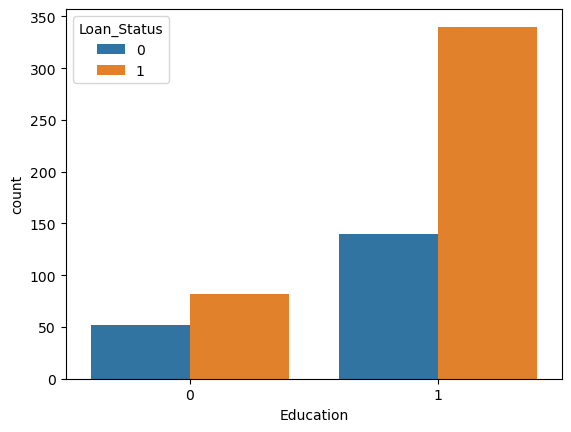

In [132]:
# Visualization using Seaborn

#isualizing loan status based on education

import seaborn as sns
import matplotlib.pyplot as plt

sns.countplot(x= 'Education', hue='Loan_Status', data=loan_filled)
#plt.show()

<Axes: xlabel='Married', ylabel='count'>

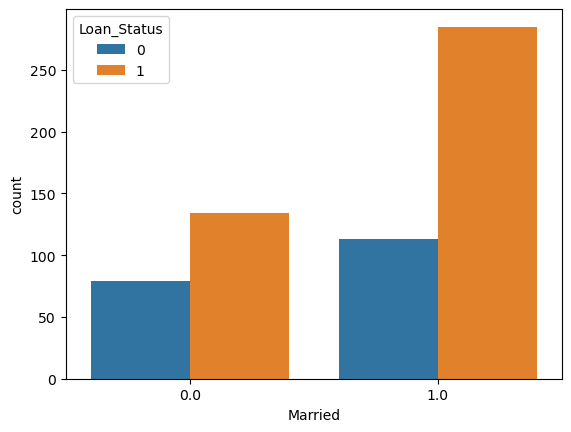

In [133]:
#Visualizing based on the marital status of applicant

sns.countplot(x= 'Married', hue='Loan_Status', data=loan_filled)

In [134]:
loan_filled.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,0,0.0,0,1,0,5849,0.0,146.412162,360.0,1.0,2,1
1,LP001003,0,1.0,1,1,0,4583,1508.0,128.000000,360.0,1.0,0,0
2,LP001005,0,1.0,0,1,1,3000,0.0,66.000000,360.0,1.0,2,1
3,LP001006,0,1.0,0,0,0,2583,2358.0,120.000000,360.0,1.0,2,1
4,LP001008,0,0.0,0,1,0,6000,0.0,141.000000,360.0,1.0,2,1


In [135]:
x = loan_filled.drop(columns = ['Loan_ID', 'Loan_Status'], axis=1)
y = loan_filled['Loan_Status']

In [136]:
x_test, x_train, y_test, y_train = train_test_split(x, y, test_size=0.3, random_state=42)

In [137]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, accuracy_score

dt_clf = DecisionTreeClassifier(max_depth=3, random_state=42)
dt_clf.fit(x_train, y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,3
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [139]:
y_pred = dt_clf.predict(x_test)

print('Accuracy:', accuracy_score(y_test, y_pred))

Accuracy: 0.7855477855477856


In [140]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.72      0.46      0.56       127
           1       0.80      0.92      0.86       302

    accuracy                           0.79       429
   macro avg       0.76      0.69      0.71       429
weighted avg       0.78      0.79      0.77       429

